# 10. RNA versus protein: do the two layers tell the same story?

The suicide vs control differences at the protein level (this re-analysis; men, 11 vs 13, model with TMT set) are compared, gene by gene, with the differences at the RNA level in an independent public RNA-seq study of the same brain region:

**GSE101521** (Pantazatos et al. 2017, *Mol Psychiatry*): dorsolateral prefrontal cortex (BA9), total RNA-seq; depressed suicide decedents (MDD-S) versus controls.

The two cohorts are different people from different countries, so this is not a within-donor comparison. It asks whether a transcript-level signature of suicide in one cohort predicts the protein-level signature in another. That is the question a single-layer study cannot answer, and the reason MOSAIC-S measures RNA and protein in the same donors.

Inputs: RNA counts from GEO; sample annotation from the public repository `wkuban/cyp46a1-suicide-dlpfc` (derived from the GEO series matrix); HGNC gene table; `results/group_comparison_with_covariates.tsv` from notebook 09.

In [1]:
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RES = ROOT / "results"; EXT = ROOT / "data_external"; (EXT / "gse101521").mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

SOURCES = {
    EXT / "gse101521" / "GSE101521_totalRNA_counts.csv.gz": "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE101nnn/GSE101521/suppl/GSE101521_totalRNA_counts.csv.gz",
    EXT / "gse101521" / "gse101521_samples.csv": "https://raw.githubusercontent.com/wkuban/cyp46a1-suicide-dlpfc/main/data/metadata/gse101521_samples.csv",
    EXT / "hgnc_complete_set.txt": "https://storage.googleapis.com/public-download-files/hgnc/tsv/tsv/hgnc_complete_set.txt",
}
for path, url in SOURCES.items():
    if not path.exists():
        urllib.request.urlretrieve(url, path)
    print(path.name, round(path.stat().st_size / 1e6, 1), "MB")

GSE101521_totalRNA_counts.csv.gz 12.6 MB
gse101521_samples.csv 0.0 MB
hgnc_complete_set.txt 17.0 MB


## RNA: suicide versus control

Counts are converted to log2(CPM + 1); genes with a mean CPM of at least 1 are kept. Linear model per gene: group + age + sex + RIN + brain pH + post-mortem interval (the model used in the CYP46A1 study). A second model uses men only, to match the protein comparison.

In [2]:
cnt = pd.read_csv(EXT / "gse101521" / "GSE101521_totalRNA_counts.csv.gz", index_col=0)
cnt.index = [str(i).split(".")[0] for i in cnt.index]; cnt = cnt[~cnt.index.duplicated()]
sm = pd.read_csv(EXT / "gse101521" / "gse101521_samples.csv").set_index("column")
sm = sm.loc[[c for c in cnt.columns if c in sm.index]]; cnt = cnt[sm.index]
cpm = cnt / cnt.sum(axis=0) * 1e6
E = np.log2(cpm[cpm.mean(axis=1) >= 1] + 1)
cov = sm.copy()
for c in ["rin", "pmi", "ph", "age"]:
    cov[c] = pd.to_numeric(cov[c], errors="coerce"); cov[c] = cov[c].fillna(cov[c].median()); cov[c] = (cov[c] - cov[c].mean()) / cov[c].std()
cov["male"] = (cov["sex"] == "Male").astype(float)

def rna_model(sel, terms):
    g = (sm.loc[sel, "diagnosis"] == "MDD-S").to_numpy(float); Y = E.loc[:, sel].to_numpy()
    X = np.column_stack([np.ones(sel.sum())] + [cov.loc[sel, t].to_numpy() for t in terms] + [g])
    df = X.shape[0] - X.shape[1]; XtXi = np.linalg.inv(X.T @ X); B = Y @ X @ XtXi; R = Y - B @ X.T
    t = B[:, -1] / np.sqrt((R ** 2).sum(axis=1) / df * XtXi[-1, -1])
    return pd.DataFrame({"ensembl": E.index, "log2FC": B[:, -1], "t": t, "p": 2 * stats.t.sf(np.abs(t), df)}), int(g.sum()), int((g == 0).sum())

two = sm["diagnosis"].isin(["CON", "MDD-S"]).to_numpy()
rna_all, a1, a0 = rna_model(two, ["age", "male", "rin", "ph", "pmi"])
rna_men, m1, m0 = rna_model(two & (sm["sex"] == "Male").to_numpy(), ["age", "rin", "ph", "pmi"])
print(f"RNA samples: {dict(sm['diagnosis'].value_counts())}; genes with mean CPM >= 1: {len(E)}")
print(f"all donors: MDD-S {a1} vs CON {a0}, genes with p < 0.05: {100 * (rna_all['p'] < 0.05).mean():.1f}%")
print(f"men only:   MDD-S {m1} vs CON {m0}, genes with p < 0.05: {100 * (rna_men['p'] < 0.05).mean():.1f}%")

RNA samples: {'CON': np.int64(29), 'MDD-S': np.int64(21), 'MDD': np.int64(9)}; genes with mean CPM >= 1: 18829
all donors: MDD-S 21 vs CON 29, genes with p < 0.05: 2.9%
men only:   MDD-S 13 vs CON 23, genes with p < 0.05: 2.5%


## Join with the protein-level comparison

In [3]:
hg = pd.read_csv(EXT / "hgnc_complete_set.txt", sep="\t", low_memory=False, usecols=["symbol", "ensembl_gene_id"]).dropna()
sym = dict(zip(hg["ensembl_gene_id"], hg["symbol"]))
def with_symbol(d, tag):
    d = d.assign(gene=d["ensembl"].map(sym)).dropna(subset=["gene"]).drop_duplicates("gene")
    return d.set_index("gene")[["log2FC", "t", "p"]].add_prefix(tag)
prot = pd.read_csv(RES / "group_comparison_with_covariates.tsv", sep="\t", index_col=0)
DF_PROTEIN = 24 - 5                                              # men: 24 donors; intercept, group, three TMT-set terms
prot["prot_t"] = np.sign(prot["log2FC_men"]) * stats.t.isf(prot["p_men"] / 2, DF_PROTEIN)
M = prot[["log2FC_men", "p_men", "prot_t"]].rename(columns={"log2FC_men": "prot_log2FC", "p_men": "prot_p"}) \
    .join(with_symbol(rna_all, "rna_"), how="inner").join(with_symbol(rna_men, "rnaM_"), how="left")
M.to_csv(RES / "rna_vs_protein_by_gene.tsv", sep="\t")
print(len(M), "genes with both a protein-level and an RNA-level estimate")

8073 genes with both a protein-level and an RNA-level estimate


In [4]:
rng = np.random.default_rng(1)
def spearman_ci(a, b, n_boot=1000):
    ok = (a.notna() & b.notna()).to_numpy(); x, y = a.to_numpy()[ok], b.to_numpy()[ok]
    r, p = stats.spearmanr(x, y)
    boot = [stats.spearmanr(x[i], y[i])[0] for i in (rng.integers(0, len(x), len(x)) for _ in range(n_boot))]
    return len(x), r, np.percentile(boot, 2.5), np.percentile(boot, 97.5), p
rows = [("RNA (all donors) vs protein (men), t statistics", *spearman_ci(M["rna_t"], M["prot_t"])),
        ("RNA (men) vs protein (men), t statistics", *spearman_ci(M["rnaM_t"], M["prot_t"])),
        ("RNA (all donors) vs protein (men), log2 fold change", *spearman_ci(M["rna_log2FC"], M["prot_log2FC"]))]
cor = pd.DataFrame(rows, columns=["comparison", "genes", "Spearman rho", "CI 2.5%", "CI 97.5%", "p"])
cor.to_csv(RES / "rna_vs_protein_correlations.tsv", sep="\t", index=False)
cor.round(4)

,comparison,genes,Spearman rho,CI 2.5%,CI 97.5%,p
0,"RNA (all donors) vs protein (men), t statistics",8073,-0.0540,-0.0754,-0.0328,0.0000
1,"RNA (men) vs protein (men), t statistics",8073,-0.0147,-0.0367,0.0057,0.1866
2,"RNA (all donors) vs protein (men), log2 fold c...",8073,-0.0569,-0.0788,-0.0348,0.0000


In [5]:
sig_r, sig_p = M["rna_p"] < 0.05, M["prot_p"] < 0.05
both = M[sig_r & sig_p]; same = int((np.sign(both["rna_t"]) == np.sign(both["prot_t"])).sum())
expected = len(M) * sig_r.mean() * sig_p.mean()
print(f"genes with p < 0.05: RNA {int(sig_r.sum())} ({100 * sig_r.mean():.1f}%), protein {int(sig_p.sum())} ({100 * sig_p.mean():.1f}%), both {len(both)} (expected if independent: {expected:.0f})")
print(f"same direction among those significant in both: {same}/{len(both)} = {100 * same / len(both):.0f}% (binomial test against 50%: p = {stats.binomtest(same, len(both), 0.5).pvalue:.3f})")
print(f"protein p < 0.05 with no RNA signal (RNA p > 0.5): {int((sig_p & (M['rna_p'] > 0.5)).sum())} genes")
focus = ["CYP46A1", "CYP27A1", "CYP51A1", "POR", "HMGCR", "DHCR24", "SLC17A7", "SNAP25", "SYP", "GFAP", "AQP4", "NR3C1", "FKBP5", "S100A10", "ALDH2", "GSTT1", "GSTP1"]
M.loc[[g for g in focus if g in M.index], ["rna_log2FC", "rna_p", "prot_log2FC", "prot_p"]].round(3)

genes with p < 0.05: RNA 229 (2.8%), protein 1701 (21.1%), both 55 (expected if independent: 48)
same direction among those significant in both: 22/55 = 40% (binomial test against 50%: p = 0.177)
protein p < 0.05 with no RNA signal (RNA p > 0.5): 910 genes


,rna_log2FC,rna_p,prot_log2FC,prot_p
CYP46A1,-0.057,0.640,0.013,0.818
CYP27A1,0.034,0.847,-0.046,0.464
CYP51A1,-0.017,0.845,-0.057,0.112
POR,-0.059,0.372,-0.012,0.538
HMGCR,0.003,0.975,-0.068,0.251
DHCR24,0.078,0.513,0.328,0.008
SLC17A7,-0.093,0.671,0.046,0.310
SNAP25,0.035,0.896,-0.025,0.313
SYP,0.049,0.830,0.077,0.044
GFAP,-0.005,0.983,0.166,0.305


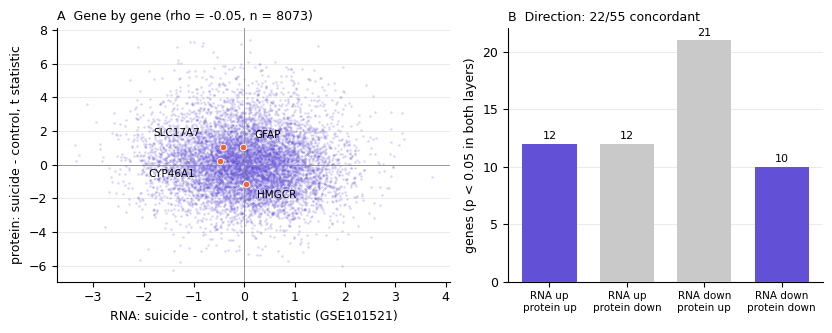

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(8.4, 3.4), gridspec_kw={"width_ratios": [1.25, 1]})
ax[0].scatter(M["rna_t"], M["prot_t"], s=3, color="#6250d6", alpha=0.25, linewidths=0, zorder=2)
ax[0].axhline(0, color="#888888", lw=0.6); ax[0].axvline(0, color="#888888", lw=0.6)
for g, off in [("CYP46A1", (-52, -12)), ("SLC17A7", (-50, 8)), ("GFAP", (8, 6)), ("HMGCR", (8, -10))]:
    if g in M.index:
        ax[0].scatter(M.loc[g, "rna_t"], M.loc[g, "prot_t"], s=22, color="#eb6834", edgecolor="white", linewidth=0.6, zorder=4)
        ax[0].annotate(g, (M.loc[g, "rna_t"], M.loc[g, "prot_t"]), xytext=off, textcoords="offset points", fontsize=7.5)
ax[0].set_xlabel("RNA: suicide - control, t statistic (GSE101521)"); ax[0].set_ylabel("protein: suicide - control, t statistic")
ax[0].set_title(f"A  Gene by gene (rho = {cor['Spearman rho'].iloc[0]:.2f}, n = {len(M)})", fontsize=9, loc="left")
quad = pd.crosstab(np.sign(both["rna_t"]).map({1: "RNA up", -1: "RNA down"}), np.sign(both["prot_t"]).map({1: "protein up", -1: "protein down"}))
labels, vals = [], []
for r in ["RNA up", "RNA down"]:
    for c in ["protein up", "protein down"]:
        labels.append(f"{r}\n{c}"); vals.append(int(quad.loc[r, c]) if r in quad.index and c in quad.columns else 0)
colors = ["#6250d6", "#c9c9c9", "#c9c9c9", "#6250d6"]
ax[1].bar(range(4), vals, color=colors, width=0.7, zorder=3)
for i, v in enumerate(vals): ax[1].text(i, v + max(vals) * 0.02, str(v), ha="center", fontsize=8)
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(labels, fontsize=7.5); ax[1].set_ylabel("genes (p < 0.05 in both layers)"); ax[1].yaxis.get_major_locator().set_params(integer=True)
ax[1].set_title(f"B  Direction: {same}/{len(both)} concordant", fontsize=9, loc="left")
for a in ax:
    a.grid(axis="y", color="#e6e6e6", lw=0.6); a.set_axisbelow(True)
fig.tight_layout(); fig.savefig(RES / "fig_rna_vs_protein.png", dpi=300); plt.show()

## Conclusions

- Across about 8,000 genes there is no positive relationship between the RNA-level and the protein-level difference between suicide and control (Spearman rho close to zero, slightly negative).
- Genes significant in both layers are no more frequent than expected by chance, and their directions agree no more often than a coin toss.
- Many proteins differ between the groups without any RNA signal for the same gene.

Limits. The two cohorts differ in country, diagnosis (depressed suicide decedents versus suicide decedents of mixed psychiatric history), sex composition and circumstances of death, and the RNA study has few genes with a detectable group effect. The absence of agreement therefore cannot be assigned to biology (post-transcriptional regulation) or to the cohorts.

That ambiguity is the point: transcript-level findings from one cohort cannot stand in for protein-level changes in another. Resolving it needs both layers, and the genome, from the same donors and the same tissue blocks, which is the design of MOSAIC-S.